In [ ]:
import pandas as pd
import math
from collections import Counter


# ==================================================
# 1. INPUT - DU LIEU VA CAU HINH
# ==================================================

data = pd.DataFrame({
    "Troi": [
        "Nang", "Nang", "Am u", "Mua", "Mua",
        "Mua", "Am u", "Nang", "Nang", "Mua"
    ],

    "Nhiet_do": [
        "Nong", "Nong", "Nong", "Vua", "Mat",
        "Mat", "Mat", "Vua", "Mat", "Vua"
    ],

    "Do_am": [
        "Cao", "Cao", "Cao", "Cao", "Binh thuong",
        "Binh thuong", "Binh thuong", "Cao",
        "Binh thuong", "Binh thuong"
    ],

    "Gio": [
        "Yeu", "Manh", "Yeu", "Yeu", "Yeu",
        "Manh", "Manh", "Yeu", "Yeu", "Yeu"
    ],

    "Ket_qua": [
        "Khong", "Khong", "Co", "Co", "Co",
        "Khong", "Co", "Khong", "Co", "Co"
    ]
})

TARGET = "Ket_qua"


# ==================================================
# 2. XU LY - THUAT TOAN ID3
# ==================================================

# ---------- ENTROPY ----------

def entropy(data, target):
    counts = Counter(data[target])
    total = len(data)

    result = 0
    terms = []

    for count in counts.values():
        p = count / total
        result -= p * math.log2(p)

        terms.append(
            f"-({count}/{total})*log2({count}/{total})"
        )

    return result, " + ".join(terms), counts


# ---------- ENTROPY SAU KHI CHIA ----------

def split_entropy(data, attribute, target):
    total = len(data)
    weighted = 0
    parts = []
    details = []

    for value, subset in data.groupby(attribute, sort=False):
        n = len(subset)
        h, formula, counts = entropy(subset, target)

        weighted += (n / total) * h
        parts.append(f"({n}/{total})*{h:.4f}")

        details.append({
            "value": value,
            "size": n,
            "counts": counts,
            "entropy": h,
            "formula": formula
        })

    return weighted, " + ".join(parts), details


# ---------- INFORMATION GAIN ----------

def information_gain(data, attribute, target):
    h_parent, _, _ = entropy(data, target)

    h_after, formula, details = split_entropy(
        data, attribute, target
    )

    gain = h_parent - h_after

    return gain, h_parent, h_after, formula, details


# ---------- IN CHI TIET THUOC TINH DUOC CHON ----------

def print_selected_attribute(data, attribute, target, indent=""):
    gain, h_parent, h_after, formula, details = (
        information_gain(data, attribute, target)
    )

    print(f"\n{indent}CHI TIET THUOC TINH: {attribute}")

    for item in details:
        print(
            f"\n{indent}- {attribute} = {item['value']}: "
            f"{item['size']} mau "
            f"({', '.join(f'{k}: {v}' for k, v in item['counts'].items())})"
        )

        if item["entropy"] == 0:
            print(f"{indent}  Entropy = 0 (tap thuan nhat)")
        else:
            print(f"{indent}  Entropy = {item['formula']}")
            print(f"{indent}           = {item['entropy']:.4f}")

    print(f"\n{indent}Entropy(D|{attribute})")
    print(f"{indent}= {formula}")
    print(f"{indent}= {h_after:.4f}")

    print(f"\n{indent}Gain(D, {attribute})")
    print(f"{indent}= Entropy(D) - Entropy(D|{attribute})")
    print(f"{indent}= {h_parent:.4f} - {h_after:.4f}")
    print(f"{indent}= {gain:.4f}")


# ---------- ID3 ----------

def ID3(data, target, attributes, level=0):
    indent = "    " * level

    counts = Counter(data[target])
    total = len(data)

    print("\n" + "=" * 60)
    print(f"{indent}XET TAP DU LIEU D ({total} MAU)")
    print(
        f"{indent}Phan bo lop: "
        + ", ".join(f"{k}: {v}" for k, v in counts.items())
    )

    # Tap du lieu rong
    if total == 0:
        return {"leaf": None}

    # Tap du lieu thuan nhat
    if len(counts) == 1:
        result = next(iter(counts))

        print(f"{indent}Entropy(D) = 0")
        print(f"{indent}=> Nut la: {result}")

        return {"leaf": result}

    # Het thuoc tinh
    if not attributes:
        majority = counts.most_common(1)[0][0]

        print(f"{indent}Het thuoc tinh.")
        print(f"{indent}=> Chon lop da so: {majority}")

        return {"leaf": majority}

    # Entropy tap hien tai
    h, formula, _ = entropy(data, target)

    print(f"\n{indent}1. ENTROPY")
    print(f"{indent}Entropy(D)")
    print(f"{indent}= {formula}")
    print(f"{indent}= {h:.4f}")

    # Tinh Gain tat ca thuoc tinh
    print(f"\n{indent}2. SO SANH INFORMATION GAIN")

    gains = {}

    for attribute in attributes:
        gain, _, _, _, _ = information_gain(
            data, attribute, target
        )

        gains[attribute] = gain

        print(
            f"{indent}Gain(D, {attribute}) = {gain:.4f}"
        )

    # Chon thuoc tinh co Gain lon nhat
    best_attribute = max(gains, key=gains.get)
    best_gain = gains[best_attribute]

    print(
        f"\n{indent}=> Chon {best_attribute} "
        f"(Gain = {best_gain:.4f})"
    )

    # Gain bang 0
    if best_gain <= 1e-12:
        majority = counts.most_common(1)[0][0]

        print(f"{indent}Khong the phan chia tiep.")
        print(f"{indent}=> Nut la: {majority}")

        return {"leaf": majority}

    # In chi tiet thuoc tinh duoc chon
    print_selected_attribute(
        data, best_attribute, target, indent
    )

    # Tao cac nhanh
    tree = {
        "attribute": best_attribute,
        "branches": {}
    }

    remaining = [
        a for a in attributes if a != best_attribute
    ]

    for value, subset in data.groupby(
        best_attribute, sort=False
    ):
        print(
            f"\n{indent}>>> XET NHANH "
            f"{best_attribute} = {value}"
        )

        subtree = ID3(
            subset,
            target,
            remaining,
            level + 1
        )

        tree["branches"][value] = subtree

    return tree


# ==================================================
# 3. OUTPUT - IN KET QUA
# ==================================================

# ---------- IN CAY QUYET DINH ----------

def print_tree(tree, indent=""):
    if "leaf" in tree:
        print(indent + "-> " + str(tree["leaf"]))
        return

    print(indent + "[" + tree["attribute"] + "]")

    branches = list(tree["branches"].items())

    for i, (value, subtree) in enumerate(branches):
        last = i == len(branches) - 1

        connector = "`-- " if last else "|-- "
        next_indent = indent + ("    " if last else "|   ")

        print(indent + connector + str(value))
        print_tree(subtree, next_indent)


# ---------- CHAY CHUONG TRINH ----------

def run_id3(data, target):
    if target not in data.columns:
        raise ValueError("Khong tim thay cot nhan!")

    if data.empty:
        raise ValueError("Bang du lieu rong!")

    if data.isnull().any().any():
        raise ValueError("Du lieu co gia tri rong!")

    attributes = [
        col for col in data.columns if col != target
    ]

    print("\n========== DU LIEU DAU VAO ==========")
    print(data.to_string(index=False))

    tree = ID3(data, target, attributes)

    print("\n\n========== CAY QUYET DINH ==========")
    print_tree(tree)

    return tree


# ---------- THUC THI ----------

tree = run_id3(data, TARGET)


========== DU LIEU DAU VAO ==========
Troi Nhiet_do       Do_am  Gio Ket_qua
Nang     Nong         Cao  Yeu   Khong
Nang     Nong         Cao Manh   Khong
Am u     Nong         Cao  Yeu      Co
 Mua      Vua         Cao  Yeu      Co
 Mua      Mat Binh thuong  Yeu      Co
 Mua      Mat Binh thuong Manh   Khong
Am u      Mat Binh thuong Manh      Co
Nang      Vua         Cao  Yeu   Khong
Nang      Mat Binh thuong  Yeu      Co
 Mua      Vua Binh thuong  Yeu      Co

XET TAP DU LIEU D (10 MAU)
Phan bo lop: Khong: 4, Co: 6

1. ENTROPY
Entropy(D)
= -(4/10)*log2(4/10) + -(6/10)*log2(6/10)
= 0.9710

2. SO SANH INFORMATION GAIN
Gain(D, Troi) = 0.3219
Gain(D, Nhiet_do) = 0.0955
Gain(D, Do_am) = 0.1245
Gain(D, Gio) = 0.0913

=> Chon Troi (Gain = 0.3219)

CHI TIET THUOC TINH: Troi

- Troi = Nang: 4 mau (Khong: 3, Co: 1)
  Entropy = -(3/4)*log2(3/4) + -(1/4)*log2(1/4)
           = 0.8113

- Troi = Am u: 2 mau (Co: 2)
  Entropy = 0 (tap thuan nhat)

- Troi = Mua: 4 mau (Co: 3, Khong: 1)
  Entropy =

In [ ]:
import pandas as pd
import numpy as np


# ==================================================
# 1. INPUT - NHẬP DỮ LIỆU VÀ CẤU HÌNH
# ==================================================

# Đề 3: 7 quan sát, Manhattan, k = 3, tâm khởi tạo A1, A4, A6
# (Đề 1: A1(5,3) A2(15,12) A3(10,15) A4(24,10) A5(30,45) A6(85,70) A7(71,80)
#        A8(60,78) A9(55,52) A10(80,91); Euclid, K = 2, tâm A1, A3)
data = pd.DataFrame({
    "Điểm": ["A1", "A2", "A3", "A4", "A5", "A6", "A7"],
    "X": [1, 2, 8, 5, 7, 2, 6],
    "Y": [2, 5, 4, 8, 5, 10, 4]
})

K = 3

INITIAL_CENTROIDS = [
    [1, 2],     # A1
    [5, 8],     # A4
    [2, 10]     # A6
]

DISTANCE_METHOD = "euclidean"  # "euclidean" hoặc "manhattan"
MAX_ITER = 100
DIGITS = 3


# ==================================================
# 2. XỬ LÝ - THUẬT TOÁN K-MEANS
# ==================================================

def k_means(data, k, initial_centroids,
            distance_method="euclidean", max_iter=100):

    df = data.copy().reset_index(drop=True)

    point_names = df.iloc[:, 0].astype(str).to_numpy()
    X = df.iloc[:, 1:].to_numpy(dtype=float)

    centroids = np.array(initial_centroids, dtype=float)

    # Kiểm tra dữ liệu đầu vào
    if not 1 <= k <= len(X):
        raise ValueError("K không hợp lệ!")

    if centroids.shape != (k, X.shape[1]):
        raise ValueError("Tâm cụm không hợp lệ!")

    if distance_method not in ["euclidean", "manhattan"]:
        raise ValueError("Phương pháp khoảng cách không hợp lệ!")

    if not np.isfinite(X).all() or not np.isfinite(centroids).all():
        raise ValueError("Dữ liệu không được chứa NaN hoặc vô cực!")

    history = []
    labels = None
    converged = False

    for step in range(1, max_iter + 1):

        old_centroids = centroids.copy()

        # Tính khoảng cách
        if distance_method == "euclidean":
            distances = np.array([
                [np.linalg.norm(point - c) for c in centroids]
                for point in X
            ])
        else:
            distances = np.array([
                [np.sum(np.abs(point - c)) for c in centroids]
                for point in X
            ])

        # Gán điểm vào cụm gần nhất
        new_labels = np.argmin(distances, axis=1)

        # Cập nhật tâm cụm
        new_centroids = centroids.copy()
        clusters = []
        calculations = []

        for j in range(k):

            members = X[new_labels == j]
            member_names = point_names[new_labels == j]

            if len(members) > 0:
                new_centroids[j] = members.mean(axis=0)

                calculations.append({
                    "members": member_names.tolist(),
                    "values": members.copy(),
                    "mean": new_centroids[j].copy(),
                    "empty": False
                })

            else:
                calculations.append({
                    "members": [],
                    "values": np.array([]),
                    "mean": centroids[j].copy(),
                    "empty": True
                })

            clusters.append(members.copy())

        # Kiểm tra hội tụ
        stable = (
            labels is not None
            and np.array_equal(new_labels, labels)
        )

        # Lưu kết quả từng vòng lặp
        history.append({
            "step": step,
            "centroids": old_centroids,
            "distances": distances.copy(),
            "labels": new_labels.copy(),
            "clusters": clusters,
            "calculations": calculations,
            "new_centroids": new_centroids.copy(),
            "stable": stable
        })

        labels = new_labels.copy()
        centroids = new_centroids.copy()

        if stable:
            converged = True
            break

    # Kết quả cuối cùng
    final_result = df.copy()
    final_result["Cụm"] = [
        f"C{x+1}" for x in labels
    ]

    return {
        "history": history,
        "result": final_result,
        "centroids": centroids,
        "converged": converged
    }


# Chạy thuật toán
result = k_means(
    data=data,
    k=K,
    initial_centroids=INITIAL_CENTROIDS,
    distance_method=DISTANCE_METHOD,
    max_iter=MAX_ITER
)


# ==================================================
# 3. OUTPUT - IN LỜI GIẢI VÀ KẾT QUẢ
# ==================================================

def fmt(x):
    return f"{x:.{DIGITS}f}"


def fmt_point(point):
    return "(" + ", ".join(fmt(x) for x in point) + ")"


# Dữ liệu ban đầu
print("\n========== DU LIEU BAN DAU ==========")
print(data.to_string(index=False))

# Cấu hình
print("\n========== CAU HINH ==========")
print(f"So cum K = {K}")
print(f"Phuong phap: {DISTANCE_METHOD}")
print(f"So vong lap toi da: {MAX_ITER}")

# Công thức
print("\n========== CONG THUC ==========")

if DISTANCE_METHOD == "euclidean":
    print("Euclidean: d(P,C) = sqrt[Σ(xi - ci)^2]")
else:
    print("Manhattan: d(P,C) = Σ|xi - ci|")

print("Cap nhat tam cum: Cj = Mean(cac diem thuoc cum Cj)")


# In từng vòng lặp
for item in result["history"]:

    step = item["step"]
    centroids = item["centroids"]
    distances = item["distances"]
    labels = item["labels"]
    calculations = item["calculations"]
    new_centroids = item["new_centroids"]

    print(f"\n\n========== VONG LAP {step} ==========")

    # --------------------------------------------------
    # 1. Tâm cụm hiện tại
    # --------------------------------------------------

    print("\n1. TAM CUM HIEN TAI")

    for j, c in enumerate(centroids):
        print(f"C{j+1} = {fmt_point(c)}")

    # --------------------------------------------------
    # 2. Tính khoảng cách và phân cụm
    # --------------------------------------------------

    print("\n2. TINH KHOANG CACH VA PHAN CUM")

    # Tạo tên điểm kèm tọa độ
    point_labels = []

    for i in range(len(data)):
        name = data.iloc[i, 0]
        coordinates = data.iloc[i, 1:].to_numpy(dtype=float)

        point_labels.append(
            f"{name}{fmt_point(coordinates)}"
        )

    distance_result = pd.DataFrame({
        "Điểm": point_labels
    })

    for j in range(K):
        distance_result[f"d(C{j+1})"] = [
            fmt(x) for x in distances[:, j]
        ]

    distance_result["Cụm"] = [
        f"C{x+1}" for x in labels
    ]

    print(distance_result.to_string(index=False))

    # Thống kê các điểm thuộc từng cụm
    print("\nTap cac diem thuoc cac cum:")

    for j in range(K):
        members = data.iloc[np.where(labels == j)[0], 0].tolist()

        print(f"C{j+1}: [{', '.join(members)}]")

    # --------------------------------------------------
    # 3. Cập nhật tâm cụm
    # --------------------------------------------------

    print("\n3. CAP NHAT TAM CUM")

    for j, calc in enumerate(calculations):

        print(f"\nC{j+1}:")

        if calc["empty"]:
            print("Cum rong, giu nguyen tam cum.")
            continue

        values = calc["values"]
        names = calc["members"]

        print(f"Cac diem: [{', '.join(names)}]")

        for col, column_name in enumerate(data.columns[1:]):

            values_col = values[:, col]

            expression = " + ".join(
                fmt(x) for x in values_col
            )

            print(
                f"{column_name}: ({expression})"
                f" / {len(values_col)}"
                f" = {fmt(calc['mean'][col])}"
            )

        print(
            f"=> Tam moi C{j+1} = "
            f"{fmt_point(new_centroids[j])}"
        )

    # --------------------------------------------------
    # 4. Kiểm tra hội tụ
    # --------------------------------------------------

    print("\n4. KIEM TRA HOI TU")

    if item["stable"]:
        print("Cac diem khong doi cum.")
        print("=> THUAT TOAN HOI TU.")
    else:
        print("Cac diem thay doi cum, tiep tuc lap.")


# --------------------------------------------------
# Kết quả cuối cùng
# --------------------------------------------------

print("\n\n========== KET QUA CUOI CUNG ==========")

print(result["result"].to_string(index=False))

print("\nTAM CUM CUOI CUNG")

for j, c in enumerate(result["centroids"]):
    print(f"C{j+1} = {fmt_point(c)}")

if result["converged"]:
    print("\nKet luan: Thuat toan K-means da hoi tu.")
else:
    print("\nKet luan: Dat so vong lap toi da, chua xac nhan hoi tu.")


========== DU LIEU BAN DAU ==========
Điểm  X  Y
  A1  1  2
  A2  2  5
  A3  8  4
  A4  5  8
  A5  7  5
  A6  2 10
  A7  6  4

========== CAU HINH ==========
So cum K = 3
Phuong phap: euclidean
So vong lap toi da: 100

========== CONG THUC ==========
Euclidean: d(P,C) = sqrt[Σ(xi - ci)^2]
Cap nhat tam cum: Cj = Mean(cac diem thuoc cum Cj)


========== VONG LAP 1 ==========

1. TAM CUM HIEN TAI
C1 = (1.000, 2.000)
C2 = (5.000, 8.000)
C3 = (2.000, 10.000)

2. TINH KHOANG CACH VA PHAN CUM
             Điểm d(C1) d(C2) d(C3) Cụm
 A1(1.000, 2.000) 0.000 7.211 8.062  C1
 A2(2.000, 5.000) 3.162 4.243 5.000  C1
 A3(8.000, 4.000) 7.280 5.000 8.485  C2
 A4(5.000, 8.000) 7.211 0.000 3.606  C2
 A5(7.000, 5.000) 6.708 3.606 7.071  C2
A6(2.000, 10.000) 8.062 3.606 0.000  C3
 A7(6.000, 4.000) 5.385 4.123 7.211  C2

Tap cac diem thuoc cac cum:
C1: [A1, A2]
C2: [A3, A4, A5, A7]
C3: [A6]

3. CAP NHAT TAM CUM

C1:
Cac diem: [A1, A2]
X: (1.000 + 2.000) / 2 = 1.500
Y: (2.000 + 5.000) / 2 = 3.500
=> Tam mo


LỜI GIẢI

Dữ liệu ban đầu:
   X: [7.000, 4.500, 5.500, 6.500, 6.100, 5.300, 5.000, 5.100, 4.900, 4.600, 5.700, 5.400]
   Y: [3.200, 2.300, 3.500, 2.800, 2.800, 3.700, 3.300, 3.500, 3.000, 3.100, 4.400, 3.900]

Dữ liệu sắp xếp tăng dần:
   X: [4.500, 4.600, 4.900, 5.000, 5.100, 5.300, 5.400, 5.500, 5.700, 6.100, 6.500, 7.000]
   Y: [2.300, 2.800, 2.800, 3.000, 3.100, 3.200, 3.300, 3.500, 3.500, 3.700, 3.900, 4.400]

a) Tính Mean (Trung bình), Median (Trung vị) và Mode (Yếu vị):

   X:
   Mean = Σxᵢ / n = 65.600 / 12 = 5.467
   Median = (x₍ₙ/₂₎ + x₍ₙ/₂₊₁₎) / 2 = (5.300 + 5.400) / 2 = 5.350
   Mode: Không có.

   Y:
   Mean = Σxᵢ / n = 39.500 / 12 = 3.292
   Median = (x₍ₙ/₂₎ + x₍ₙ/₂₊₁₎) / 2 = (3.200 + 3.300) / 2 = 3.250
   Mode = [2.800, 3.500]

b) Vẽ Boxplot (Biểu đồ hộp) và xác định Outlier (Giá trị ngoại lệ):

   X:
   Nửa dưới: [4.500, 4.600, 4.900, 5.000, 5.100, 5.300]
   Nửa trên: [5.400, 5.500, 5.700, 6.100, 6.500, 7.000]
   Five-number summary (Bộ 5 số):
   Min = 4.500
   Q1 = 4.

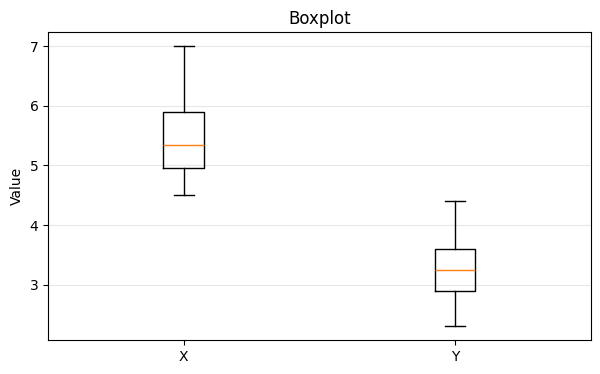


c) Chuẩn hóa dữ liệu (Normalization):
   Phương pháp: Z-score
   zᵢ = (xᵢ - x̄) / s
   s = Σ|xᵢ - x̄| / n   (độ lệch tuyệt đối trung bình)
   Một phần tử: i = chữ số cuối MSSV + 1 = 7 + 1 = 8

   X:
   Giá trị ban đầu: x8 = 5.100
   x̄ = 5.467
   s = 0.578
   z8 = (5.100 - 5.467) / 0.578 = -0.635

   Y:
   Giá trị ban đầu: x8 = 3.500
   x̄ = 3.292
   s = 0.425
   z8 = (3.500 - 3.292) / 0.425 = 0.490

d) Chia bin (Phân thùng) và làm mịn dữ liệu (Smoothing):
   Dữ liệu: both; Phương pháp chia: equal-depth; K = 3
   Phương pháp làm mịn: boundaries

   X:
   Số phần tử mỗi bin: [4, 4, 4]

   Bin 1: [4.500, 4.600, 4.900, 5.000]
   Boundaries = [4.500, 5.000]
   Thay mỗi giá trị bằng biên gần nó nhất.
   Sau làm mịn: [4.500, 4.500, 5.000, 5.000]

   Bin 2: [5.100, 5.300, 5.400, 5.500]
   Boundaries = [5.100, 5.500]
   Thay mỗi giá trị bằng biên gần nó nhất.
   Sau làm mịn: [5.100, 5.100, 5.500, 5.500]
   Lưu ý: 5.300 cách đều 2 biên -> quy ước lấy biên dưới.

   Bin 3: [5.700, 6.100, 6.500,

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ==================================================
# 1. NHẬP DỮ LIỆU VÀ CẤU HÌNH
# ==================================================

X = np.array([7, 4.5, 5.5, 6.5, 6.1, 5.3,
              5, 5.1, 4.9, 4.6, 5.7, 5.4])

Y = np.array([3.2, 2.3, 3.5, 2.8, 2.8, 3.7,
              3.3, 3.5, 3, 3.1, 4.4, 3.9])

# Câu b: Boxplot
BOXPLOT_DATA = "both"         # "X", "Y" hoặc "both"

# Câu c: Chuẩn hóa
NORM_DATA = "both"            # "X", "Y" hoặc "both"
NORM_METHOD = "zscore"        # "minmax" hoặc "zscore"
NORM_SCOPE = "single"         # "single" hoặc "all"
ID_LAST = 7                   # Chữ số cuối mã sinh viên
NORM_MIN = 1                  # Cận dưới Min-Max
NORM_MAX = 5                  # Cận trên Min-Max
NORM_SPREAD = "mad"           # Z-score: "std" = độ lệch chuẩn, "mad" = độ lệch tuyệt đối trung bình (đề 1)

# Câu d: Chia bin
BIN_DATA = "both"             # "X", "Y" hoặc "both"
BIN_METHOD = "equal-depth"    # "equal-depth" hoặc "equal-width"
K = 3                         # Số bin
SMOOTH = "boundaries"         # "means" hoặc "boundaries"
TIE_RULE = "low"              # Làm trơn biên: giá trị cách đều 2 biên -> "low" (biên dưới) hoặc "high"
EDGE_RULE = "right-closed"      # Equal-width: "right-open" = [a,b) ; "right-closed" = (a,b], bin đầu đóng

DIGITS = 3


# ==================================================
# 2. CÁC HÀM TÍNH TOÁN
# ==================================================

def descriptive(data):
    mean = np.mean(data)
    med = np.median(data)

    count = Counter(data)
    max_count = max(count.values())

    if max_count == 1:
        mode = []
    else:
        mode = sorted([
            x for x, c in count.items()
            if c == max_count
        ])

    return {
        "mean": mean,
        "median": med,
        "mode": mode
    }


def boxplot(data):
    s = np.sort(data)
    n = len(s)
    mid = n // 2

    if n % 2 == 0:
        lower = s[:mid]
        upper = s[mid:]
    else:
        lower = s[:mid]
        upper = s[mid + 1:]

    Q1 = np.median(lower)
    Q2 = np.median(s)
    Q3 = np.median(upper)

    IQR = Q3 - Q1
    LF = Q1 - 1.5 * IQR
    UF = Q3 + 1.5 * IQR

    outliers = s[(s < LF) | (s > UF)]
    normal = s[(s >= LF) & (s <= UF)]

    return {
        "min": np.min(s),
        "Q1": Q1,
        "Q2": Q2,
        "Q3": Q3,
        "max": np.max(s),
        "IQR": IQR,
        "LF": LF,
        "UF": UF,
        "outliers": outliers,
        "whislo": np.min(normal),
        "whishi": np.max(normal)
    }


def normalize(data, method, scope, id_last, norm_min, norm_max, spread="std"):
    mean = np.mean(data)
    if spread == "mad":
        std = np.mean(np.abs(data - mean))   # Độ lệch tuyệt đối trung bình
    elif spread == "std":
        std = np.std(data)                   # Độ lệch chuẩn tổng thể (chia n)
    else:
        raise ValueError("spread phải là 'std' hoặc 'mad'.")
    min_val = np.min(data)
    max_val = np.max(data)

    if method == "zscore":
        if std == 0:
            values = np.zeros(len(data))
        else:
            values = (data - mean) / std

    elif method == "minmax":
        if max_val == min_val:
            values = np.full(len(data), norm_min)
        else:
            values = norm_min + (
                (data - min_val) / (max_val - min_val)
            ) * (norm_max - norm_min)
    else:
        raise ValueError("Phương pháp chuẩn hóa không hợp lệ.")

    if scope == "single":
        i = id_last + 1

        if i < 1 or i > len(data):
            raise ValueError("Vị trí i nằm ngoài dữ liệu.")

        return {
            "scope": scope,
            "i": i,
            "original": data[i - 1],
            "value": values[i - 1],
            "mean": mean,
            "std": std,
            "min": min_val,
            "max": max_val,
            "norm_min": norm_min,
            "norm_max": norm_max
        }

    if scope == "all":
        return {
            "scope": scope,
            "values": values,
            "mean": mean,
            "std": std,
            "min": min_val,
            "max": max_val,
            "norm_min": norm_min,
            "norm_max": norm_max
        }

    raise ValueError("Phạm vi chuẩn hóa không hợp lệ.")


def smooth_values(values, smooth, tie_rule):
    """Làm trơn 1 bin. Trả về (giá trị mới, danh sách giá trị cách đều 2 biên)."""
    if smooth == "means":
        return np.full(len(values), np.mean(values)), []

    if smooth == "boundaries":
        low, high = np.min(values), np.max(values)
        new_values, ties = [], []
        for x in values:
            d_low = round(float(x - low), 9)
            d_high = round(float(high - x), 9)
            if d_low < d_high:
                new_values.append(low)
            elif d_high < d_low:
                new_values.append(high)
            else:                                   # cách đều 2 biên
                new_values.append(low if tie_rule == "low" else high)
                if low != high:
                    ties.append(x)
        return np.array(new_values), ties

    raise ValueError("Phương pháp làm mịn không hợp lệ.")


def binning(data, method, k, smooth, tie_rule="low", edge_rule="right-open"):
    if k < 1 or k > len(data):
        raise ValueError("Số bin K không hợp lệ.")

    order = np.argsort(data, kind="stable")
    s = data[order]

    bins = []
    smooth_sorted = np.zeros(len(data))

    if method == "equal-depth":
        groups = np.array_split(np.arange(len(data)), k)
        intervals = [None] * k

    elif method == "equal-width":
        edges = np.round(np.linspace(np.min(data), np.max(data), k + 1), 9)
        s_r = np.round(s, 9)
        side = "right" if edge_rule == "right-open" else "left"
        bin_id = np.searchsorted(edges[1:-1], s_r, side=side)
        groups = [np.where(bin_id == j)[0] for j in range(k)]

        intervals = []
        for j in range(k):
            a, b = edges[j], edges[j + 1]
            if edge_rule == "right-open":
                intervals.append(f"[{a:.3f}; {b:.3f}{']' if j == k - 1 else ')'}")
            else:
                intervals.append(f"{'[' if j == 0 else '('}{a:.3f}; {b:.3f}]")
    else:
        raise ValueError("Phương pháp chia bin không hợp lệ.")

    for j, idx in enumerate(groups):
        values = s[idx]

        if len(values) == 0:
            bins.append({"values": values, "smoothed": values,
                         "ties": [], "interval": intervals[j]})
            continue

        new_values, ties = smooth_values(values, smooth, tie_rule)
        smooth_sorted[idx] = new_values
        bins.append({"values": values, "smoothed": new_values,
                     "ties": ties, "interval": intervals[j]})

    final = np.zeros(len(data))
    final[order] = smooth_sorted

    return {
        "bins": bins,
        "final": final,
        "sorted": s
    }


def pearson(X, Y):
    return np.corrcoef(X, Y)[0, 1]


def correlation_level(r):
    a = abs(r)
    if a < 0.1:
        return "gần như không có tương quan tuyến tính"
    if a < 0.3:
        return "tương quan yếu"
    if a < 0.5:
        return "tương quan trung bình"
    if a < 0.7:
        return "tương quan khá mạnh"
    return "tương quan mạnh"


# ==================================================
# 3. TÍNH TOÁN VÀ LƯU KẾT QUẢ
# ==================================================

result = {
    "a": {},
    "b": {},
    "c": {},
    "d": {},
    "e": {}
}

# Câu a
result["a"]["X"] = descriptive(X)
result["a"]["Y"] = descriptive(Y)

# Câu b
result["b"]["X"] = boxplot(X)
result["b"]["Y"] = boxplot(Y)

result["b"]["boxplot"] = [
    {
        "label": "X",
        "whislo": result["b"]["X"]["whislo"],
        "q1": result["b"]["X"]["Q1"],
        "med": result["b"]["X"]["Q2"],
        "q3": result["b"]["X"]["Q3"],
        "whishi": result["b"]["X"]["whishi"],
        "fliers": result["b"]["X"]["outliers"]
    },
    {
        "label": "Y",
        "whislo": result["b"]["Y"]["whislo"],
        "q1": result["b"]["Y"]["Q1"],
        "med": result["b"]["Y"]["Q2"],
        "q3": result["b"]["Y"]["Q3"],
        "whishi": result["b"]["Y"]["whishi"],
        "fliers": result["b"]["Y"]["outliers"]
    }
]

# Câu c
result["c"]["method"] = NORM_METHOD
result["c"]["scope"] = NORM_SCOPE
result["c"]["data"] = NORM_DATA

if NORM_DATA in ["X", "both"]:
    result["c"]["X"] = normalize(
        X, NORM_METHOD, NORM_SCOPE, ID_LAST, NORM_MIN, NORM_MAX, NORM_SPREAD
    )

if NORM_DATA in ["Y", "both"]:
    result["c"]["Y"] = normalize(
        Y, NORM_METHOD, NORM_SCOPE, ID_LAST, NORM_MIN, NORM_MAX, NORM_SPREAD
    )

# Câu d
result["d"]["method"] = BIN_METHOD
result["d"]["k"] = K
result["d"]["smooth"] = SMOOTH
result["d"]["data"] = BIN_DATA

if BIN_DATA in ["X", "both"]:
    result["d"]["X"] = binning(X, BIN_METHOD, K, SMOOTH, TIE_RULE, EDGE_RULE)

if BIN_DATA in ["Y", "both"]:
    result["d"]["Y"] = binning(Y, BIN_METHOD, K, SMOOTH, TIE_RULE, EDGE_RULE)

# Câu e
result["e"]["r"] = pearson(X, Y)


# ==================================================
# 4. IN LỜI GIẢI
# ==================================================

def fmt(x):
    return f"{x:.{DIGITS}f}"


def fmt_list(data):
    return ", ".join(fmt(x) for x in data)


print("\nLỜI GIẢI")

# In dữ liệu ban đầu và dữ liệu đã sắp xếp
print("\nDữ liệu ban đầu:")
for name, data in [("X", X), ("Y", Y)]:
    print(f"   {name}: [{fmt_list(data)}]")

print("\nDữ liệu sắp xếp tăng dần:")
for name, data in [("X", X), ("Y", Y)]:
    print(f"   {name}: [{fmt_list(np.sort(data))}]")


# ---------------- Câu a ----------------

print("\na) Tính Mean (Trung bình), Median (Trung vị) và Mode (Yếu vị):")

for name, data in [("X", X), ("Y", Y)]:
    r = result["a"][name]
    s = np.sort(data)
    n = len(data)

    print(f"\n   {name}:")
    print(
        f"   Mean = Σxᵢ / n = {np.sum(data):.3f} / {n}"
        f" = {fmt(r['mean'])}"
    )

    if n % 2 == 0:
        mid = n // 2
        print(
            f"   Median = (x₍ₙ/₂₎ + x₍ₙ/₂₊₁₎) / 2"
            f" = ({fmt(s[mid-1])} + {fmt(s[mid])}) / 2"
            f" = {fmt(r['median'])}"
        )
    else:
        mid = n // 2
        print(
            f"   Median = x₍₍ₙ₊₁₎/₂₎ = {fmt(s[mid])}"
        )

    if len(r["mode"]) == 0:
        print("   Mode: Không có.")
    else:
        print(f"   Mode = [{fmt_list(r['mode'])}]")


# ---------------- Câu b ----------------

print("\nb) Vẽ Boxplot (Biểu đồ hộp) và xác định Outlier (Giá trị ngoại lệ):")

for name, data in [("X", X), ("Y", Y)]:
    if BOXPLOT_DATA not in [name, "both"]:
        continue

    r = result["b"][name]
    s = np.sort(data)
    mid = len(s) // 2
    lower = s[:mid]
    upper = s[mid:] if len(s) % 2 == 0 else s[mid+1:]

    print(f"\n   {name}:")
    print(f"   Nửa dưới: [{fmt_list(lower)}]")
    print(f"   Nửa trên: [{fmt_list(upper)}]")

    print("   Five-number summary (Bộ 5 số):")
    print(f"   Min = {fmt(r['min'])}")
    print(f"   Q1 = {fmt(r['Q1'])}")
    print(f"   Q2 = {fmt(r['Q2'])}")
    print(f"   Q3 = {fmt(r['Q3'])}")
    print(f"   Max = {fmt(r['max'])}")

    print(
        f"   IQR = Q3 - Q1 = {fmt(r['Q3'])} - {fmt(r['Q1'])}"
        f" = {fmt(r['IQR'])}"
    )
    print(
        f"   LF = Q1 - 1.5 × IQR = {fmt(r['Q1'])}"
        f" - 1.5 × {fmt(r['IQR'])} = {fmt(r['LF'])}"
    )
    print(
        f"   UF = Q3 + 1.5 × IQR = {fmt(r['Q3'])}"
        f" + 1.5 × {fmt(r['IQR'])} = {fmt(r['UF'])}"
    )

    if len(r["outliers"]) == 0:
        print("   Outlier: Không có.")
    else:
        print(f"   Outlier: [{fmt_list(r['outliers'])}]")

    print(
        f"   Whiskers (Râu) = "
        f"[{fmt(r['whislo'])}, {fmt(r['whishi'])}]"
    )

# Chỉ vẽ các tập dữ liệu được chọn
selected_boxplots = [
    item for item in result["b"]["boxplot"]
    if BOXPLOT_DATA == "both" or item["label"] == BOXPLOT_DATA
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bxp(selected_boxplots, showfliers=True)
ax.set_title("Boxplot")
ax.set_ylabel("Value")
ax.grid(axis="y", alpha=0.3)
plt.show()


# ---------------- Câu c ----------------

print("\nc) Chuẩn hóa dữ liệu (Normalization):")

if NORM_METHOD == "zscore":
    print("   Phương pháp: Z-score")
    if NORM_SPREAD == "mad":
        print("   zᵢ = (xᵢ - x̄) / s")
        print("   s = Σ|xᵢ - x̄| / n   (độ lệch tuyệt đối trung bình)")
    else:
        print("   zᵢ = (xᵢ - x̄) / σ")
        print("   σ = √[Σ(xᵢ - x̄)² / n]   (độ lệch chuẩn tổng thể)")
else:
    print("   Phương pháp: Min-Max")
    print(
        f"   x' = a + [(x - Min) / (Max - Min)] × (b - a)"
        f"; khoảng đích [{NORM_MIN}, {NORM_MAX}]"
    )

if NORM_SCOPE == "single":
    print(
        f"   Một phần tử: i = chữ số cuối MSSV + 1"
        f" = {ID_LAST} + 1 = {ID_LAST + 1}"
    )
else:
    print("   Phạm vi: Toàn bộ dữ liệu")

for name, data in [("X", X), ("Y", Y)]:
    if name not in result["c"]:
        continue

    r = result["c"][name]
    print(f"\n   {name}:")

    if NORM_SCOPE == "single":
        print(f"   Giá trị ban đầu: x{r['i']} = {fmt(r['original'])}")

        if NORM_METHOD == "zscore":
            print(f"   x̄ = {fmt(r['mean'])}")
            print(f"   {'s' if NORM_SPREAD == 'mad' else 'σ'} = {fmt(r['std'])}")
            print(
                f"   z{r['i']} = ({fmt(r['original'])}"
                f" - {fmt(r['mean'])}) / {fmt(r['std'])}"
                f" = {fmt(r['value'])}"
            )
        else:
            print(f"   Min = {fmt(r['min'])}; Max = {fmt(r['max'])}")
            print(
                f"   x' = {NORM_MIN} + [({fmt(r['original'])}"
                f" - {fmt(r['min'])}) / ({fmt(r['max'])}"
                f" - {fmt(r['min'])})] × ({NORM_MAX} - {NORM_MIN})"
                f" = {fmt(r['value'])}"
            )
    else:
        print(f"   Kết quả: [{fmt_list(r['values'])}]")


# ---------------- Câu d ----------------

print("\nd) Chia bin (Phân thùng) và làm mịn dữ liệu (Smoothing):")
print(f"   Dữ liệu: {BIN_DATA}; Phương pháp chia: {BIN_METHOD}; K = {K}")
print(f"   Phương pháp làm mịn: {SMOOTH}")

for name, data in [("X", X), ("Y", Y)]:
    if name not in result["d"]:
        continue

    r = result["d"][name]
    print(f"\n   {name}:")

    if BIN_METHOD == "equal-width":
        width = (np.max(data) - np.min(data)) / K
        print(
            f"   Width = (Max - Min) / K"
            f" = ({fmt(np.max(data))} - {fmt(np.min(data))}) / {K}"
            f" = {fmt(width)}"
        )
    else:
        sizes = [len(b["values"]) for b in r["bins"]]
        print(f"   Số phần tử mỗi bin: {sizes}")

    for j, b in enumerate(r["bins"], 1):
        if len(b["values"]) == 0:
            continue

        if b["interval"]:
            print(f"\n   Bin {j} {b['interval']}: [{fmt_list(b['values'])}]")
        else:
            print(f"\n   Bin {j}: [{fmt_list(b['values'])}]")

        if SMOOTH == "means":
            mean_bin = np.mean(b["values"])
            print(
                f"   Bin Mean = Σxᵢ / n"
                f" = {np.sum(b['values']):.3f} / {len(b['values'])}"
                f" = {fmt(mean_bin)}"
            )
        else:
            low = np.min(b["values"])
            high = np.max(b["values"])
            print(f"   Boundaries = [{fmt(low)}, {fmt(high)}]")
            print("   Thay mỗi giá trị bằng biên gần nó nhất.")

        print(f"   Sau làm mịn: [{fmt_list(b['smoothed'])}]")
        if b["ties"]:
            side = "biên dưới" if TIE_RULE == "low" else "biên trên"
            print(f"   Lưu ý: {fmt_list(b['ties'])} cách đều 2 biên -> quy ước lấy {side}.")

    print(f"\n   Kết quả cuối cùng: [{fmt_list(r['final'])}]")


# ---------------- Câu e ----------------

print("\ne) Tính hệ số tương quan Pearson (Pearson Correlation):")
print(
    "   r = Σ[(xᵢ - x̄)(yᵢ - ȳ)]"
    " / √[Σ(xᵢ - x̄)² × Σ(yᵢ - ȳ)²]"
)

r = result["e"]["r"]
print(f"   r = {fmt(r)}")

sign = "thuận" if r > 0 else "nghịch" if r < 0 else ""
print(f"   |r| = {fmt(abs(r))} -> {correlation_level(r)}" + (f" ({sign})." if abs(r) >= 0.1 else "."))


In [ ]:
from itertools import combinations
from math import ceil


def fs(itemset):
    return "{" + ", ".join(sorted(itemset)) + "}"


# ==================================================
# 1. INPUT - DU LIEU VA CAU HINH
# ==================================================

transactions = {
    "T1": ["F", "M", "B", "E"],
    "T2": ["O", "F", "E"],
    "T3": ["O", "A", "H", "S"],
    "T4": ["D", "B", "F", "E"],
    "T5": ["D", "A", "H", "S"],
    "T6": ["O", "M", "E"],
    "T7": ["O", "A", "D", "H", "S"]
}

MIN_SUPPORT = 40
MIN_CONFIDENCE = 75


# ==================================================
# 2. XU LY - THUAT TOAN APRIORI
# ==================================================

def apriori(transactions, min_support):

    total = len(transactions)

    normalized = {
        tid: sorted(items)
        for tid, items in transactions.items()
    }

    data = [
        set(items) for items in normalized.values()
    ]

    min_count = ceil(total * min_support / 100)

    def count_support(itemset):
        return sum(
            1 for transaction in data
            if itemset.issubset(transaction)
        )

    frequent_itemsets = {}
    history = []

    # Tao C1 va L1
    items = sorted(set(
        item for transaction in data
        for item in transaction
    ))

    C1 = [frozenset([item]) for item in items]

    counts = {
        itemset: count_support(itemset)
        for itemset in C1
    }

    L1 = [
        itemset for itemset in C1
        if counts[itemset] >= min_count
    ]

    history.append({
        "k": 1,
        "C": C1,
        "counts": counts,
        "L": L1
    })

    frequent_itemsets.update({
        itemset: counts[itemset] for itemset in L1
    })

    # Sinh Ck va Lk
    L_previous = L1
    k = 2

    while L_previous:

        candidates = set()

        previous_list = sorted(
            [tuple(sorted(itemset)) for itemset in L_previous]
        )

        for i in range(len(previous_list)):
            for j in range(i + 1, len(previous_list)):

                union = set(previous_list[i]) | set(previous_list[j])

                if len(union) != k:
                    continue

                # Kiem tra cac tap con kich thuoc k-1
                valid = all(
                    frozenset(subset) in L_previous
                    for subset in combinations(sorted(union), k - 1)
                )

                if valid:
                    candidates.add(frozenset(union))

        Ck = sorted(
            candidates,
            key=lambda x: tuple(sorted(x))
        )

        if not Ck:
            history.append({
                "k": k,
                "C": [],
                "counts": {},
                "L": []
            })
            break

        counts = {
            itemset: count_support(itemset)
            for itemset in Ck
        }

        Lk = [
            itemset for itemset in Ck
            if counts[itemset] >= min_count
        ]

        history.append({
            "k": k,
            "C": Ck,
            "counts": counts,
            "L": Lk
        })

        frequent_itemsets.update({
            itemset: counts[itemset] for itemset in Lk
        })

        L_previous = Lk
        k += 1

    return normalized, frequent_itemsets, history, total, min_count


# Sinh luat ket hop

def generate_rules(frequent_itemsets, total, min_confidence):

    rules = []

    for itemset, count_union in frequent_itemsets.items():

        if len(itemset) < 2:
            continue

        for size in range(1, len(itemset)):

            for subset in combinations(sorted(itemset), size):

                A = frozenset(subset)
                B = itemset - A

                count_A = frequent_itemsets.get(A)

                if count_A is None or count_A == 0:
                    continue

                support = count_union / total * 100
                confidence = count_union / count_A * 100

                rules.append({
                    "A": A,
                    "B": B,
                    "support": support,
                    "confidence": confidence,
                    "strong": confidence >= min_confidence
                })

    return rules


# ==================================================
# 3. OUTPUT - IN KET QUA
# ==================================================

def print_output(frequent_itemsets, history, rules, total, min_count):

    print("\n========== KET QUA APRIORI ==========")

    print("\na) TIM CAC TAP MUC PHO BIEN")

    print(f"N = {total}")
    print(f"minsup = {MIN_SUPPORT}%")
    print(f"min_count = ⌈N × minsup / 100⌉ = {min_count}")

    print("\nCong thuc:")
    print("Support(X) = Count(X) / N × 100%")
    print("Lk = {X ∈ Ck | Support(X) ≥ minsup}")

    for step in history:

        k = step["k"]
        C = step["C"]
        counts = step["counts"]
        L = step["L"]

        print(f"\nC{k}:")

        if not C:
            print("∅")
        else:
            for itemset in C:
                print(f"{fs(itemset)}: {counts[itemset]}")

        print(f"L{k}:")

        if not L:
            print("∅")
        else:
            for itemset in L:
                print(f"{fs(itemset)}: {counts[itemset]}")

    print("\nTong hop cac tap muc pho bien:")

    for itemset, count in sorted(
        frequent_itemsets.items(),
        key=lambda x: (len(x[0]), tuple(sorted(x[0])))
    ):
        support = count / total * 100

        print(
            f"{fs(itemset)}: "
            f"Count = {count}, Support = {support:.2f}%"
        )

    print("\nb) TIM CAC LUAT KET HOP MANH")

    print("Support(A → B) = Support(A ∪ B)")
    print("Confidence(A → B) = Count(A ∪ B) / Count(A) × 100%")
    print("Strong Rule ⇔ Confidence(A → B) ≥ minconf")

    print(f"\nminconf = {MIN_CONFIDENCE}%")

    print(
        f"\n{'Rule':<22}"
        f"{'Support (%)':<16}"
        f"{'Confidence (%)':<18}"
        f"{'Result'}"
    )

    strong_count = 0

    for rule in rules:

        A = rule["A"]
        B = rule["B"]

        support = rule["support"]
        confidence = rule["confidence"]
        strong = rule["strong"]

        result = "Strong" if strong else "Not Strong"

        if strong:
            strong_count += 1

        rule_name = f"{fs(A)} → {fs(B)}"

        print(
            f"{rule_name:<22}"
            f"{support:<16.2f}"
            f"{confidence:<18.2f}"
            f"{result}"
        )

    print(f"\nTong so luat ket hop manh: {strong_count}")


# ==================================================
# GOI CHUONG TRINH
# ==================================================

normalized, frequent_itemsets, history, total, min_count = apriori(
    transactions, MIN_SUPPORT
)

rules = generate_rules(
    frequent_itemsets, total, MIN_CONFIDENCE
)

print_output(
    frequent_itemsets,
    history,
    rules,
    total,
    min_count
)


========== KET QUA APRIORI ==========

a) TIM CAC TAP MUC PHO BIEN
N = 7
minsup = 40%
min_count = ⌈N × minsup / 100⌉ = 3

Cong thuc:
Support(X) = Count(X) / N × 100%
Lk = {X ∈ Ck | Support(X) ≥ minsup}

C1:
{A}: 3
{B}: 2
{D}: 3
{E}: 4
{F}: 3
{H}: 3
{M}: 2
{O}: 4
{S}: 3
L1:
{A}: 3
{D}: 3
{E}: 4
{F}: 3
{H}: 3
{O}: 4
{S}: 3

C2:
{A, D}: 2
{A, E}: 0
{A, F}: 0
{A, H}: 3
{A, O}: 2
{A, S}: 3
{D, E}: 1
{D, F}: 1
{D, H}: 2
{D, O}: 1
{D, S}: 2
{E, F}: 3
{E, H}: 0
{E, O}: 2
{E, S}: 0
{F, H}: 0
{F, O}: 1
{F, S}: 0
{H, O}: 2
{H, S}: 3
{O, S}: 2
L2:
{A, H}: 3
{A, S}: 3
{E, F}: 3
{H, S}: 3

C3:
{A, H, S}: 3
L3:
{A, H, S}: 3

C4:
∅
L4:
∅

Tong hop cac tap muc pho bien:
{A}: Count = 3, Support = 42.86%
{D}: Count = 3, Support = 42.86%
{E}: Count = 4, Support = 57.14%
{F}: Count = 3, Support = 42.86%
{H}: Count = 3, Support = 42.86%
{O}: Count = 4, Support = 57.14%
{S}: Count = 3, Support = 42.86%
{A, H}: Count = 3, Support = 42.86%
{A, S}: Count = 3, Support = 42.86%
{E, F}: Count = 3, Support = 42.86

In [ ]:
from itertools import combinations
from math import ceil


def fs(itemset):
    return "{" + ", ".join(sorted(itemset)) + "}"


# ==================================================
# 1. INPUT - DU LIEU VA CAU HINH
# ==================================================

transactions = {
    "T1": ["F", "M", "B", "E"],
    "T2": ["O", "F", "E"],
    "T3": ["O", "A", "H", "S"],
    "T4": ["D", "B", "F", "E"],
    "T5": ["D", "A", "H", "S"],
    "T6": ["O", "M", "E"],
    "T7": ["O", "A", "D", "H", "S"]
}

MIN_SUPPORT = 40
MIN_CONFIDENCE = 75


# ==================================================
# 2. XU LY - THUAT TOAN FP-GROWTH
# ==================================================

# Cau truc nut trong FP-Tree
class Node:

    def __init__(self, item, count, parent):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}


# Xay dung FP-Tree
def build_tree(transactions, min_count):

    # Dem Support Count cua tung item
    item_counts = {}

    for items, weight in transactions:
        for item in items:
            item_counts[item] = (
                item_counts.get(item, 0) + weight
            )

    # Loai item khong dat Min Support
    item_counts = {
        item: count
        for item, count in item_counts.items()
        if count >= min_count
    }

    if not item_counts:
        return None, {}

    # Thu tu item theo Support giam dan
    order = sorted(
        item_counts,
        key=lambda x: (-item_counts[x], x)
    )

    rank = {
        item: i for i, item in enumerate(order)
    }

    root = Node(None, 0, None)

    # Header Table: luu cac nut cung item
    header = {
        item: [] for item in item_counts
    }

    # Chen tung giao dich vao FP-Tree
    for items, weight in transactions:

        filtered = [
            item for item in items
            if item in item_counts
        ]

        filtered.sort(key=lambda x: rank[x])

        current = root

        for item in filtered:

            if item not in current.children:

                child = Node(item, 0, current)
                current.children[item] = child
                header[item].append(child)

            current = current.children[item]
            current.count += weight

    return root, header


# Khai thac FP-Tree
def mine_tree(header, suffix, frequent_itemsets):

    # Xet item tu Support nho den lon
    items = sorted(
        header,
        key=lambda x: (sum(n.count for n in header[x]), x)
    )

    for item in items:

        nodes = header[item]

        support_count = sum(
            node.count for node in nodes
        )

        new_itemset = suffix | frozenset([item])

        frequent_itemsets[new_itemset] = support_count

        # Tao Conditional Pattern Base
        conditional_base = []

        for node in nodes:

            path = []
            parent = node.parent

            while parent is not None and parent.item is not None:
                path.append(parent.item)
                parent = parent.parent

            if path:
                conditional_base.append(
                    (path, node.count)
                )

        # Tao Conditional FP-Tree
        if conditional_base:

            conditional_tree, conditional_header = build_tree(
                conditional_base,
                MIN_COUNT
            )

            if conditional_tree is not None:
                mine_tree(
                    conditional_header,
                    new_itemset,
                    frequent_itemsets
                )


# In FP-Tree
def print_tree(node, level=0):

    for item, child in node.children.items():

        print(
            "  " * level +
            f"{item}:{child.count}"
        )

        print_tree(child, level + 1)


# Thuat toan FP-Growth
def fp_growth(transactions, min_support):

    total = len(transactions)

    min_count = ceil(
        total * min_support / 100
    )

    # Chuyen giao dich thanh dang co trong so
    data = [
        (items, 1)
        for items in transactions.values()
    ]

    root, header = build_tree(data, min_count)

    frequent_itemsets = {}

    if root is not None:
        mine_tree(
            header,
            frozenset(),
            frequent_itemsets
        )

    return root, frequent_itemsets, total, min_count


# Sinh luat ket hop
def generate_rules(frequent_itemsets, total, min_confidence):

    rules = []

    for itemset, count_union in frequent_itemsets.items():

        if len(itemset) < 2:
            continue

        for size in range(1, len(itemset)):

            for subset in combinations(sorted(itemset), size):

                A = frozenset(subset)
                B = itemset - A

                count_A = frequent_itemsets.get(A)

                if count_A is None or count_A == 0:
                    continue

                support = count_union / total * 100
                confidence = count_union / count_A * 100

                rules.append({
                    "A": A,
                    "B": B,
                    "support": support,
                    "confidence": confidence,
                    "strong": confidence >= min_confidence
                })

    return rules


# ==================================================
# 3. OUTPUT - IN KET QUA
# ==================================================

def print_output(root, frequent_itemsets, rules, total, min_count):

    print("\n========== KET QUA FP-GROWTH ==========")

    print("\na) XAY DUNG FP-TREE")

    print(f"N = {total}")
    print(f"minsup = {MIN_SUPPORT}%")
    print(f"min_count = ⌈N × minsup / 100⌉ = {min_count}")

    print("\nSupport(X) = Count(X) / N × 100%")

    print("\nFP-Tree:")

    if root is None or not root.children:
        print("∅")
    else:
        print("ROOT")
        print_tree(root)

    print("\nb) CAC TAP MUC PHO BIEN")

    print("L = {X | Support(X) ≥ minsup}")

    if not frequent_itemsets:
        print("Khong co tap muc pho bien.")
    else:
        for itemset, count in sorted(
            frequent_itemsets.items(),
            key=lambda x: (
                len(x[0]),
                tuple(sorted(x[0]))
            )
        ):

            support = count / total * 100

            print(
                f"{fs(itemset)}: "
                f"Count = {count}, "
                f"Support = {support:.2f}%"
            )

    print("\nc) TIM CAC LUAT KET HOP MANH")

    print("Support(A → B) = Support(A ∪ B)")
    print("Confidence(A → B) = Count(A ∪ B) / Count(A) × 100%")
    print("Strong Rule ⇔ Confidence(A → B) ≥ minconf")

    print(f"\nminconf = {MIN_CONFIDENCE}%")

    print(
        f"\n{'Rule':<22}"
        f"{'Support (%)':<16}"
        f"{'Confidence (%)':<18}"
        f"{'Result'}"
    )

    strong_count = 0

    for rule in rules:

        A = rule["A"]
        B = rule["B"]

        support = rule["support"]
        confidence = rule["confidence"]
        strong = rule["strong"]

        result = "Strong" if strong else "Not Strong"

        if strong:
            strong_count += 1

        rule_name = f"{fs(A)} → {fs(B)}"

        print(
            f"{rule_name:<22}"
            f"{support:<16.2f}"
            f"{confidence:<18.2f}"
            f"{result}"
        )

    print(f"\nTong so luat ket hop manh: {strong_count}")


# ==================================================
# GOI CHUONG TRINH
# ==================================================

MIN_COUNT = ceil(
    len(transactions) * MIN_SUPPORT / 100
)

root, frequent_itemsets, total, min_count = fp_growth(
    transactions, MIN_SUPPORT
)

rules = generate_rules(
    frequent_itemsets,
    total,
    MIN_CONFIDENCE
)

print_output(
    root,
    frequent_itemsets,
    rules,
    total,
    min_count
)


========== KET QUA FP-GROWTH ==========

a) XAY DUNG FP-TREE
N = 7
minsup = 40%
min_count = ⌈N × minsup / 100⌉ = 3

Support(X) = Count(X) / N × 100%

FP-Tree:
ROOT
E:4
  F:1
  O:2
    F:1
  D:1
    F:1
O:2
  A:2
    H:1
      S:1
    D:1
      H:1
        S:1
A:1
  D:1
    H:1
      S:1

b) CAC TAP MUC PHO BIEN
L = {X | Support(X) ≥ minsup}
{A}: Count = 3, Support = 42.86%
{D}: Count = 3, Support = 42.86%
{E}: Count = 4, Support = 57.14%
{F}: Count = 3, Support = 42.86%
{H}: Count = 3, Support = 42.86%
{O}: Count = 4, Support = 57.14%
{S}: Count = 3, Support = 42.86%
{A, H}: Count = 3, Support = 42.86%
{A, S}: Count = 3, Support = 42.86%
{E, F}: Count = 3, Support = 42.86%
{H, S}: Count = 3, Support = 42.86%
{A, H, S}: Count = 3, Support = 42.86%

c) TIM CAC LUAT KET HOP MANH
Support(A → B) = Support(A ∪ B)
Confidence(A → B) = Count(A ∪ B) / Count(A) × 100%
Strong Rule ⇔ Confidence(A → B) ≥ minconf

minconf = 75%

Rule                  Support (%)     Confidence (%)    Result
{E} → {F